# Function 3 - Week 4: model predictions

A learning study using this week's **18 observations**, including the Week 3 return received on 14 October 2026.
Use [exploration](exploration.ipynb) for measured outputs, sampling coverage and the actual saved query sequence.
The model study follows the same steps as Functions 1 and 2: familiar GP pictures, held-out comparisons,
conditional curves, contour sections, uncertainty and a hypothetical model-led next point.

Three inputs plus an output require four visual quantities. Keep all three input axes in the observation cloud
and show output by colour. For model curves, hold two inputs fixed; for contours and terrains, hold one fixed.
Every picture states those held coordinates. Model predictions and the saved coverage decision remain distinct.

Run independently using the capstone-local `.venv`, with this Week 4 directory as the working directory.
The [3D plotting helpers](../../Shared/three_input_model_helpers.py) reuse the
[common fitting and query helpers](../../Shared/model_helpers.py).


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.spatial import Delaunay

week_dir = Path.cwd().resolve()
if not (week_dir / "model_predictions.ipynb").is_file() or not (week_dir / "observations.csv").is_file():
    raise FileNotFoundError("Run from Function_3/Week_04 with model_predictions.ipynb and observations.csv together.")
shared_dir = week_dir.parents[1] / "Shared"
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from query_budget import remaining_queries
from model_helpers import (
    make_models, compare_models, plot_toy_sequence, plot_validation,
    gp_slice, make_query_candidates, score_query_candidates,
)
from plot_helpers import PLOT_CONFIG
from three_input_model_helpers import (
    PLANE_AXES, input_cloud, plot_coordinate_curves, plane_grid, build_plane_slices,
    plot_contour_sections, plot_gp_score_sections, interactive_terrain_slices,
)
figures = week_dir / "figures"
figures.mkdir(exist_ok=True)
print("Kernel:", sys.executable)


Kernel: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


## 1. Begin with observations and the saved coverage point

Load all three inputs together with the measured output. No course evaluations are made here.
The one remaining point in the fixed coverage shortlist stays next; its output has not been observed.
The query allowance counts future opportunities, not the proportion of this input cube that is understood.


In [2]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ["x1", "x2", "x3"]
X = data[input_columns]
y = data["y"]
inputs = X.to_numpy(dtype=float)
raw_y = y.to_numpy(dtype=float)
if not np.isfinite(np.column_stack([inputs, raw_y])).all() or not ((inputs >= 0) & (inputs < 1)).all():
    raise ValueError("Expected finite observations with all inputs in [0, 1).")
print(f"Observations: {len(data)}; input dimensions: {inputs.shape[1]}.")
print(f"Raw output range: {raw_y.min():.6f} to {raw_y.max():.6f}.")
print(f"Queries available from the start of Week 4: {remaining_queries(week_dir)} (including this week).")


Observations: 18; input dimensions: 3.
Raw output range: -0.398926 to -0.034835.
Queries available from the start of Week 4: 10 (including this week).


In [3]:
# Fixed Week 2 plan, preserved at full precision; no optimisation is run.
planned_queries = pd.DataFrame(
    [[0.9545240919577334, 0.8194703192896731, 0.04216282607444466], [0.3523200058361702, 0.9307991516470914, 0.8498485887799658], [0.9038419399841349, 0.2689031599827457, 0.8751995976599097]],
    columns=input_columns,
)

# The first two planned points were evaluated in rounds 2 and 3.
coverage_queries = planned_queries.iloc[2:].copy()
coverage_queries

planned_inputs = coverage_queries.to_numpy(dtype=float)
actual_portal_input = "-".join(f"{value:.6f}" for value in planned_inputs[0])
print("Actual coverage-led next query:", actual_portal_input)
display(coverage_queries)


Actual coverage-led next query: 0.903842-0.268903-0.875200


,x1,x2,x3
2,0.903842,0.268903,0.8752


## 2. Learn the picture before using it on the black box

The blue line is the GP's **posterior mean**: its central prediction after seeing observations.
The pale band is **mean plus or minus 1.96 standard deviations**: a pointwise interval for the latent function under the model's assumptions.
It is not a simultaneous guarantee for the whole curve, and it excludes fresh observation noise.
Green crosses are measured values at the displayed inputs.

Only in this invented one-input example can we also draw the orange dashed **known function**.
The three panels use 3, 6 and 10 points from a fixed invented sequence. They demonstrate updating a model, not a query-selection policy.
None of these points uses the course query allowance. The GP's kernel, noise level and prior scale stay fixed across the panels.

The same visual convention is used in [scikit-learn's introductory GP example](https://scikit-learn.org/stable/auto_examples/gaussian_process/plot_gpr_noisy_targets.html).
For the actual black box we have observations and predictions, but no known orange truth curve.

In the real three-input function, the curve below will become a path through the input cube.
Two input coordinates must be held fixed before that path can be drawn against an output axis.


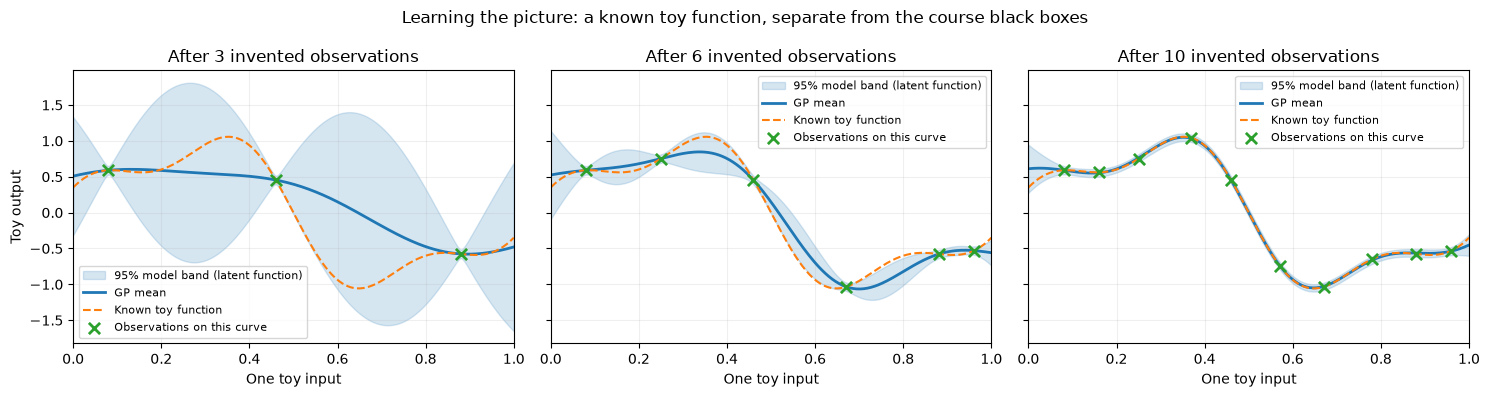

In [4]:
display(plot_toy_sequence(save_to=figures / "gp-picture-toy-sequence.png"))


## 3. Choose the target scale and a reference input

All 18 current outputs are negative, ranging from about `-0.399` to `-0.035`.
Raw outputs are readable on this range. Retain every sign and value; a less negative output is a higher score.
The GP means, standard deviations, validation errors and acquisition scores are therefore in raw output units.

Use the best observed input as a reference for the paths and sections that follow.
It is the best of these observations, not a known optimum. Holding its other coordinates fixed
lets us repeat the same GP picture along each input direction without confusing a projection with a slice.


In [5]:
model_y = raw_y.copy()
best_position = int(np.argmax(raw_y))
anchor = inputs[best_position].copy()
observation_review = data[["observation_id", *input_columns, "y"]].copy()
observation_review["observed_rank"] = y.rank(ascending=False, method="min").astype(int)
display(observation_review)
print("Reference input:", dict(zip(input_columns, anchor)))
print("Best observed output:", raw_y[best_position])


,observation_id,x1,x2,x3,y,observed_rank
0,initial-001,0.171525,0.343917,0.248737,-0.112122,14
1,initial-002,0.242114,0.644074,0.272433,-0.087963,9
2,initial-003,0.534906,0.398501,0.173389,-0.111415,13
3,initial-004,0.492581,0.611593,0.340176,-0.034835,1
4,initial-005,0.134622,0.219917,0.458206,-0.048008,4
5,initial-006,0.345523,0.941360,0.269363,-0.110621,12
6,initial-007,0.151837,0.439991,0.990882,-0.398926,18
7,initial-008,0.645503,0.397143,0.919771,-0.113869,15
8,initial-009,0.746912,0.284196,0.226300,-0.131461,17
9,initial-010,0.170477,0.697032,0.149169,-0.094190,10


Reference input: {'x1': np.float64(0.49258141463713434), 'x2': np.float64(0.6115931882759961), 'x3': np.float64(0.3401763860035727)}
Best observed output: -0.034835313350078584


## 4. Compare the same models, using all three inputs

- **Mean baseline:** predict the average of the training outputs, ignoring inputs.
- **Linear ridge:** fit a three-input plane with a coefficient penalty.
- **Quadratic ridge:** fit three linear terms, three squares and three pairwise interactions, plus an intercept.
- **Local GP:** use an RBF length scale of `0.15` in the three-input space.
- **Broad GP:** repeat with length scale `0.35`.

The ridge penalties remain `alpha=1.0`. Both GPs assume noise SD of 10% of the training output SD,
normalise targets within each fit and keep their declared kernel settings fixed.
The extra input contributes to distance: reusing a 2D length scale does not establish that it is appropriate in 3D.
These are a small set of stated hypotheses rather than an optimisation over model settings.

**Leave-one-out (LOO)** hides each result and fits the complete estimator on the other 17 rows.
Feature scaling is refitted inside each fold. Lower MAE or RMSE is better; an MAE ratio below 1 beats the training-mean baseline.
With 18 observations and ten quadratic coefficients including the intercept, smooth fitted surfaces can still predict hidden results poorly.


In [6]:
models = make_models()
comparison, held_out, fitted = compare_models(models, inputs, model_y)
best_checked_model = comparison["LOO MAE"].idxmin()
display(comparison.sort_values("LOO MAE").round(5))
print("Lowest held-out MAE among these fixed comparisons:", best_checked_model)
print("Quadratic / baseline MAE ratio:", round(comparison.loc["Quadratic ridge", "MAE / baseline"], 3))
print("Model choice on these same 18 rows can make the winning error optimistic; there is no independent test set here.")


,Training MAE,LOO MAE,LOO RMSE,MAE / baseline
Model,,,,
GP: local (l=0.15),0.00059,0.04650,0.08258,0.95010
Mean baseline,0.04622,0.04894,0.08407,1.00000
Linear ridge,0.05028,0.06686,0.09499,1.36609
GP: broad (l=0.35),0.00584,0.07613,0.09299,1.55544
Quadratic ridge,0.04535,0.08605,0.11656,1.75821


Lowest held-out MAE among these fixed comparisons: GP: local (l=0.15)
Quadratic / baseline MAE ratio: 1.758
Model choice on these same 18 rows can make the winning error optimistic; there is no independent test set here.


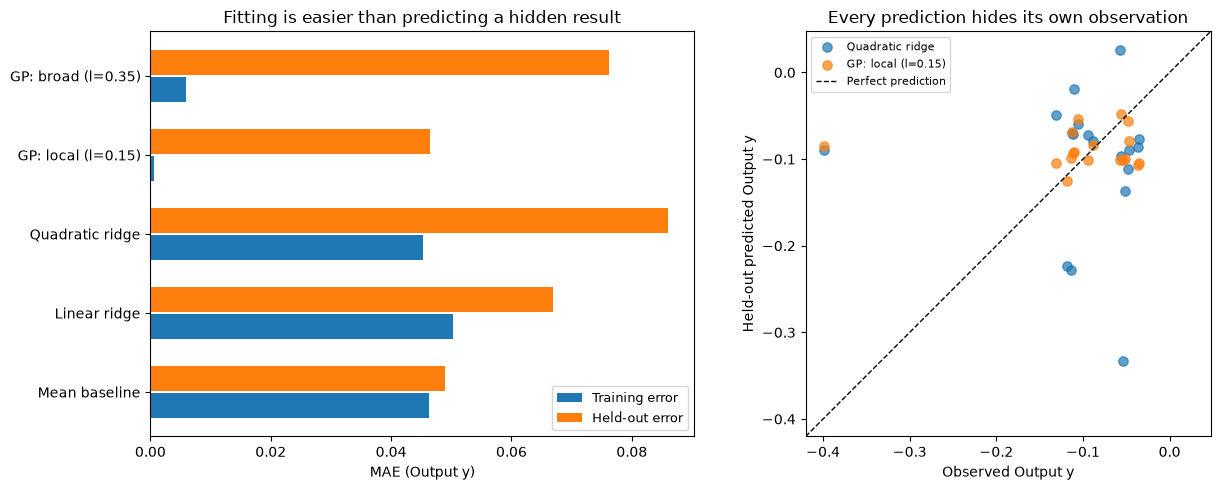

In [7]:
display(plot_validation(comparison, held_out, model_y, target_label="Output y",
                        save_to=figures / "model-comparison-validation.png"))


## 5. Locate three one-dimensional paths in the input cube

The next cloud uses `x1`, `x2`, `x3` as its three axes and measured output as colour.
Three straight paths intersect at the best observed input. Each varies one coordinate while keeping the other two fixed.
Drag the cube to see the paths from different angles.

The following response curves use **output**, rather than another input, on their vertical axis.
They are predictions along these paths. There is no known orange truth curve for the actual black box.


In [8]:
paths_fig = input_cloud(inputs, model_y, title="Function 3: where the three GP curves lie",
    anchor=anchor, save_to=figures / "gp-input-paths.html")
paths_fig.show(config=PLOT_CONFIG)


## 6. Repeat the mean, band and observations in every direction

Each column varies one named input and holds the other two at the reference values in its title.
The rows compare local and broad GPs; all six panels share output limits.
The blue curve is the GP mean, the pale area is its pointwise 95% latent-function band under the declared assumptions,
and green crosses are measurements matching **both** held coordinates.

Other observations still inform the joint GP but are not projected onto these paths.
Bands exclude fresh observation noise and uncertainty about the model itself.
They can express confidence under assumptions that the held-out checks do not support.
The paths span the input interval, including locations outside the sampled hull.


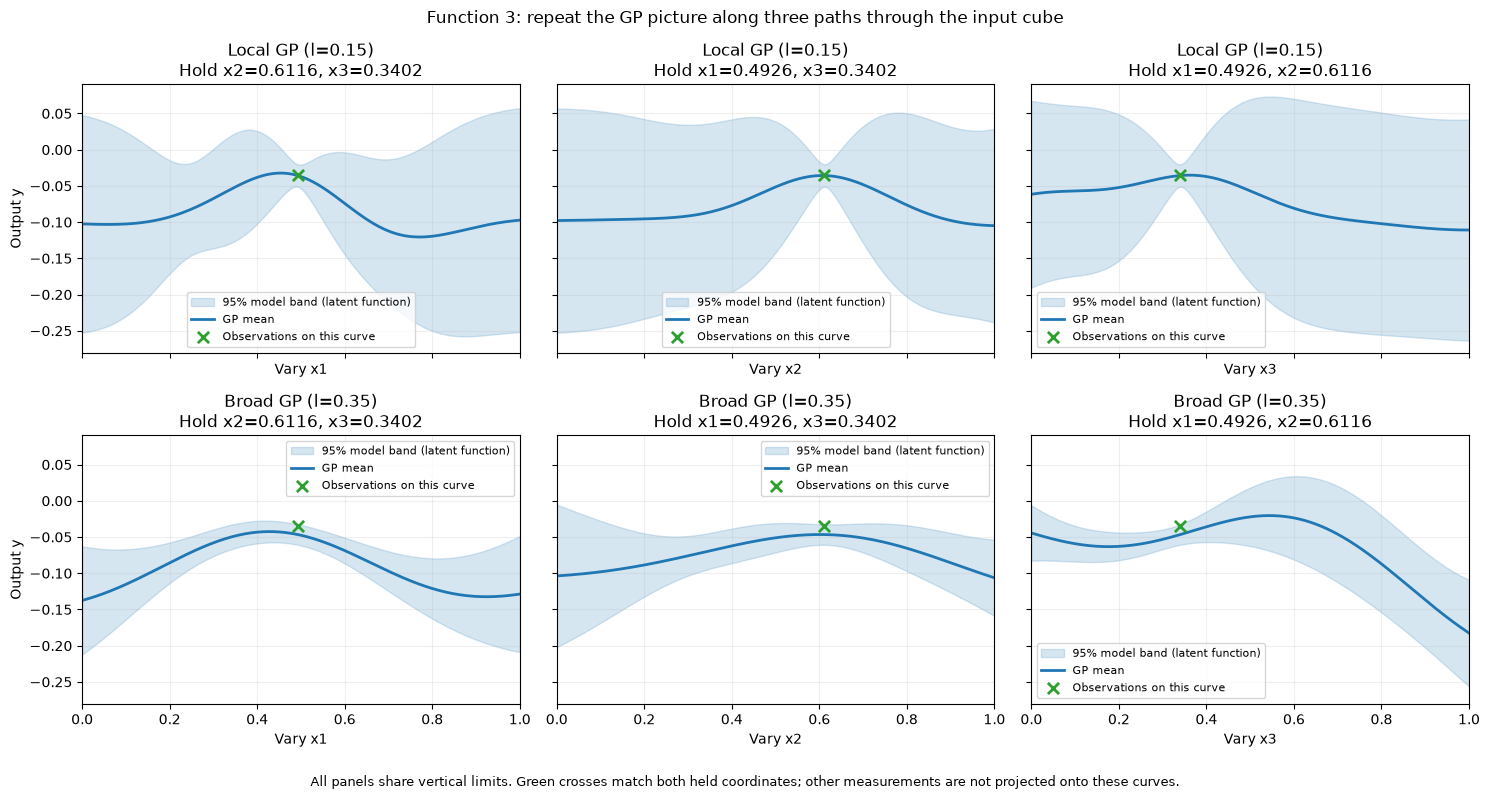

In [9]:
local_gp = fitted["GP: local (l=0.15)"]
broad_gp = fitted["GP: broad (l=0.35)"]
display(plot_coordinate_curves({"Local GP (l=0.15)": local_gp, "Broad GP (l=0.35)": broad_gp},
    inputs, model_y, anchor, save_to=figures / "gp-coordinate-slices.png"))


## 7. From a curve to a plane of contour lines

A plane varies two inputs and fixes the third. A **contour** joins points on that plane with the same fitted output.
Its level is an output value, not an observation rank or an uncertainty measure.
Closely spaced contours indicate a steeper change in this model's fitted output.

The quadratic contains all three inputs jointly:

$$\hat{y} = b_0 + b_1x_1 + b_2x_2 + b_3x_3 + b_4x_1^2 + b_5x_1x_2 + b_6x_1x_3 + b_7x_2^2 + b_8x_2x_3 + b_9x_3^2.$$

The contour matrix repeats the earlier quadratic study at held-coordinate values `0.25`, `0.50`, `0.75`.
All panels share colours and levels. Masking uses the full **3D sampled hull**, not the projected outline of an input pair.
Blank regions are outside that hull; remaining interior gaps and model uncertainty still matter.
Measurements at different held coordinates are not drawn on these planes.


Quadratic y = -0.0353 -0.0446*x1 -0.1297*x2 -0.0209*x3 -0.0692*x1^2 +0.1306*x1 x2 +0.2074*x1 x3 +0.0788*x2^2 +0.0422*x2 x3 -0.2008*x3^2


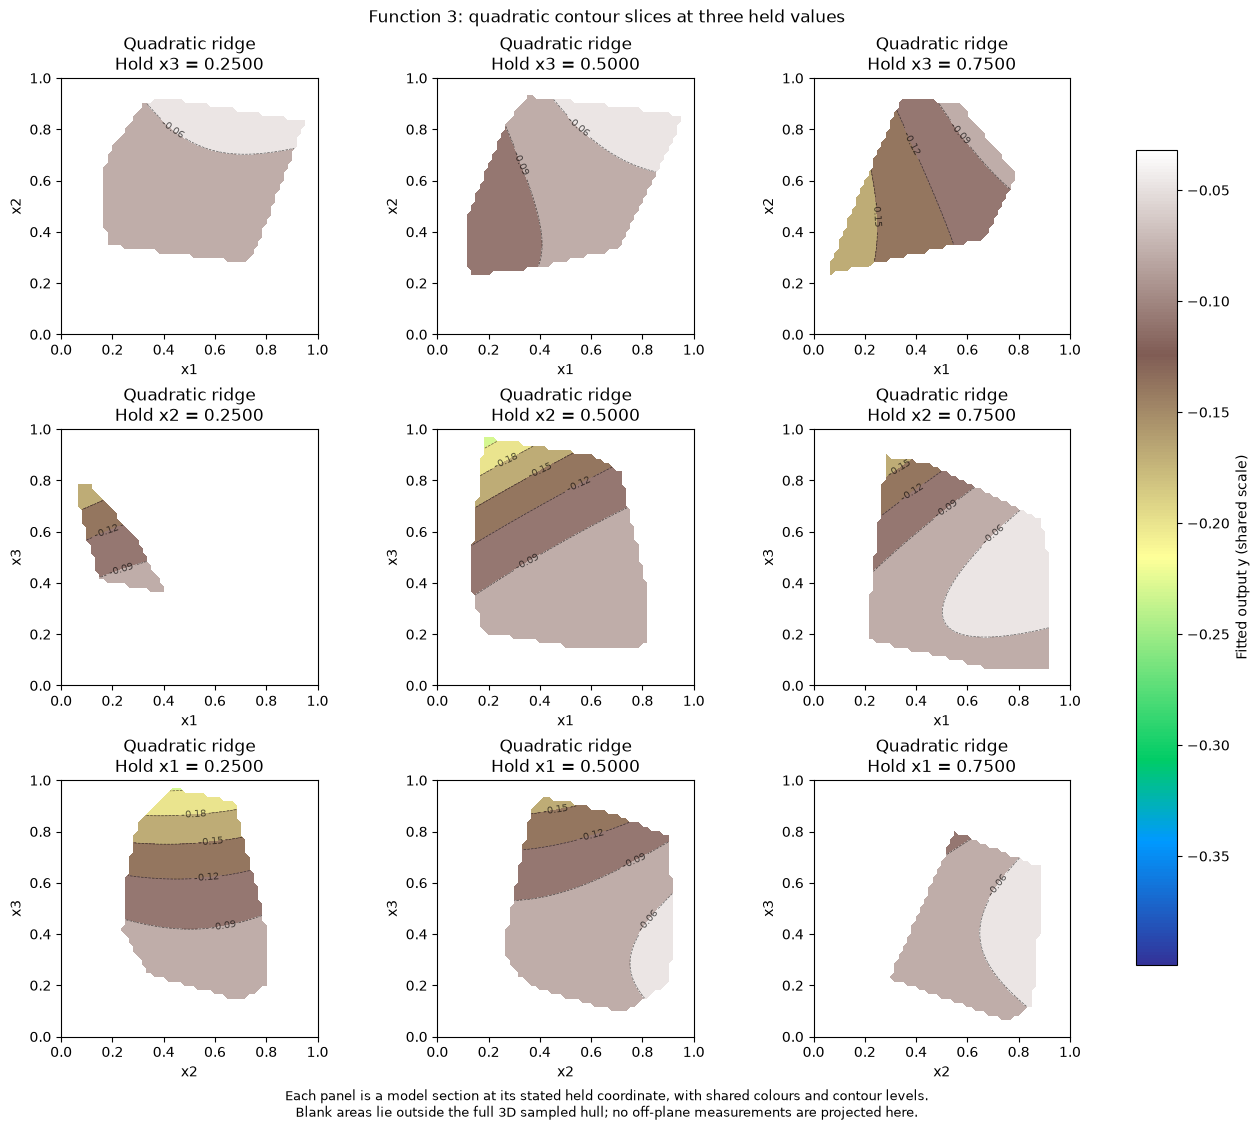

In [10]:
quadratic = fitted["Quadratic ridge"]
feature_scaler = quadratic.named_steps["standardscaler"]
regression = quadratic.named_steps["ridge"]
coefficients = regression.coef_ / feature_scaler.scale_
intercept = regression.intercept_ - coefficients @ feature_scaler.mean_
terms = quadratic.named_steps["polynomialfeatures"].get_feature_names_out(input_columns)
print("Quadratic y = " + f"{intercept:.4f}" + "".join(
    f" {coefficient:+.4f}*{term}" for coefficient, term in zip(coefficients, terms)))
slice_values = np.array([0.10, 0.25, 0.40, 0.50, 0.60, 0.75, 0.90])
quadratic_slices = build_plane_slices(quadratic, inputs, slice_values)
static_indices = [1, 3, 5]
contour_rows = [("Quadratic ridge", [quadratic_slices[level][pair] for level in static_indices]) for pair in range(3)]
display(plot_contour_sections(contour_rows, model_y,
    title="Function 3: quadratic contour slices at three held values",
    save_to=figures / "fitted-output-contour-slices.png"))


## 8. Compare models on the same sections; rotate the fitted terrain

Use a second contour matrix to compare the quadratic and local GP on the three planes through the reference input.
Each column varies the same pair in both rows, holding the third at the same value.
Shared colours allow direct comparison of the fitted output. Neither row is the true function.

The draggable quadratic terrain retains the three pairwise panels and held-input slider.
Its vertical axis is fitted output; one input is supplied by the slider. All three held inputs move to the same slider value.
It uses a `31 x 31` display grid, sampled from the finer `61 x 61` calculations, and sends only updated heights in each frame.
This reduces rendering work while retaining flat `0.16` vertical proportions. A blank panel has no intersection with the sampled hull at that value.


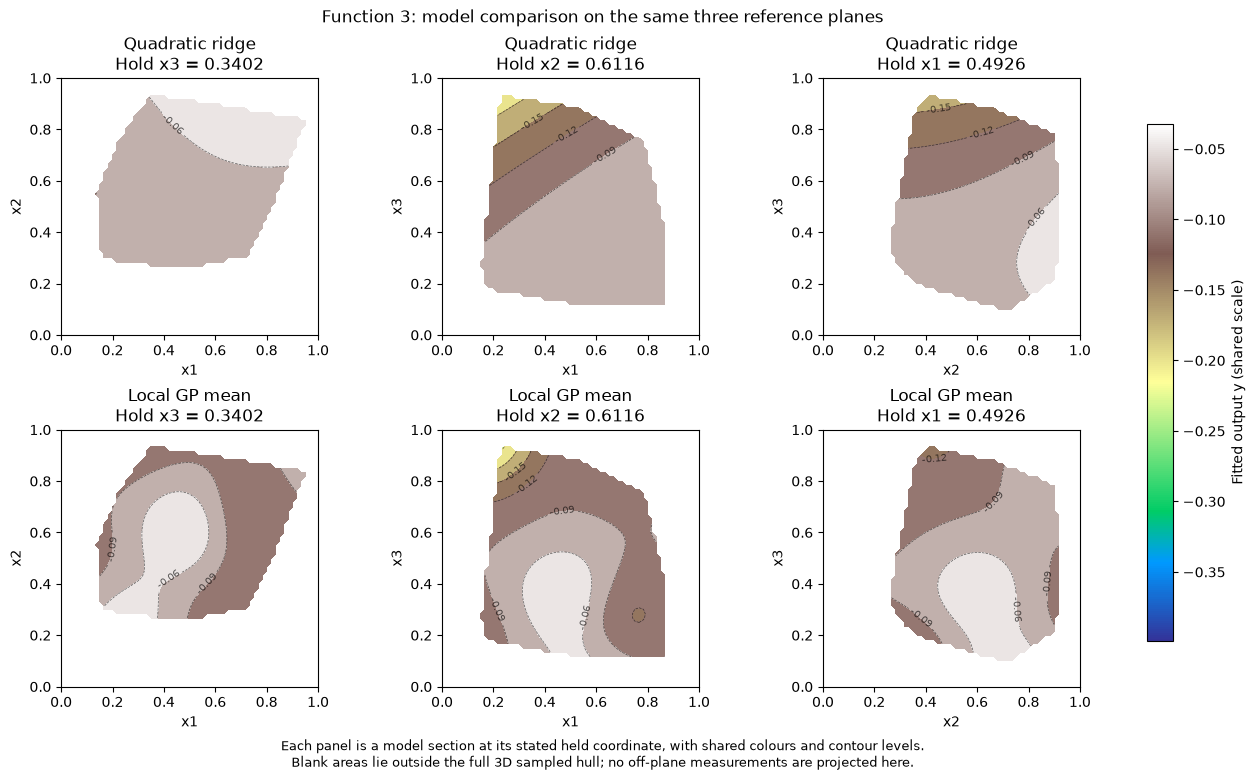

Interactive surface vertices at one slider position: 2883
Interactive figure payload: 314239 bytes (excluding the HTML JavaScript bundle).


In [11]:
anchor_quadratic_planes = [plane_grid(quadratic, inputs, (a,b), anchor[c]) for a,b,c in PLANE_AXES]
anchor_gp_planes = [plane_grid(local_gp, inputs, (a,b), anchor[c], uncertainty=True) for a,b,c in PLANE_AXES]
display(plot_contour_sections([
    ("Quadratic ridge", anchor_quadratic_planes), ("Local GP mean", anchor_gp_planes),
], model_y, title="Function 3: model comparison on the same three reference planes",
   save_to=figures / "model-mean-contour-slices.png"))
terrain_fig = interactive_terrain_slices(quadratic_slices, slice_values, model_y,
    title=f"Function 3: quadratic terrain sections; LOO MAE {comparison.loc['Quadratic ridge', 'LOO MAE']:.4f}",
    save_to=figures / "fitted-output-terrain-slices.html")
terrain_fig.show(config=PLOT_CONFIG)
print("Interactive surface vertices at one slider position:", sum(np.asarray(trace.z).size for trace in terrain_fig.data))
print("Interactive figure payload:", len(terrain_fig.to_json().encode("utf-8")), "bytes (excluding the HTML JavaScript bundle).")


## 9. Separate a high mean from high uncertainty

Repeat the mean, standard deviation and upper confidence bound on those three planes:

$$\operatorname{UCB}(x) = \mu(x) + \kappa\sigma(x), \qquad \kappa = 1.96.$$

UCB is an acquisition score, not a predicted output or a guarantee of improvement.
The weight is a declared heuristic. Each row fixes its titled coordinate and varies the two axis inputs.
Colours are shared down each column; mean, SD and UCB use their own scales.

These score panels colour the entire plane to reveal uncertainty outside the sampled hull.
The dotted boundary is the intersection with the full 3D hull. A plane with no such intersection is entirely extrapolation.
Black dots are only observations whose held coordinate matches the plane. The actual coverage point generally lies on different planes,
so it is evaluated in a table and shown in a separate 3D cloud below rather than misleadingly projected here.


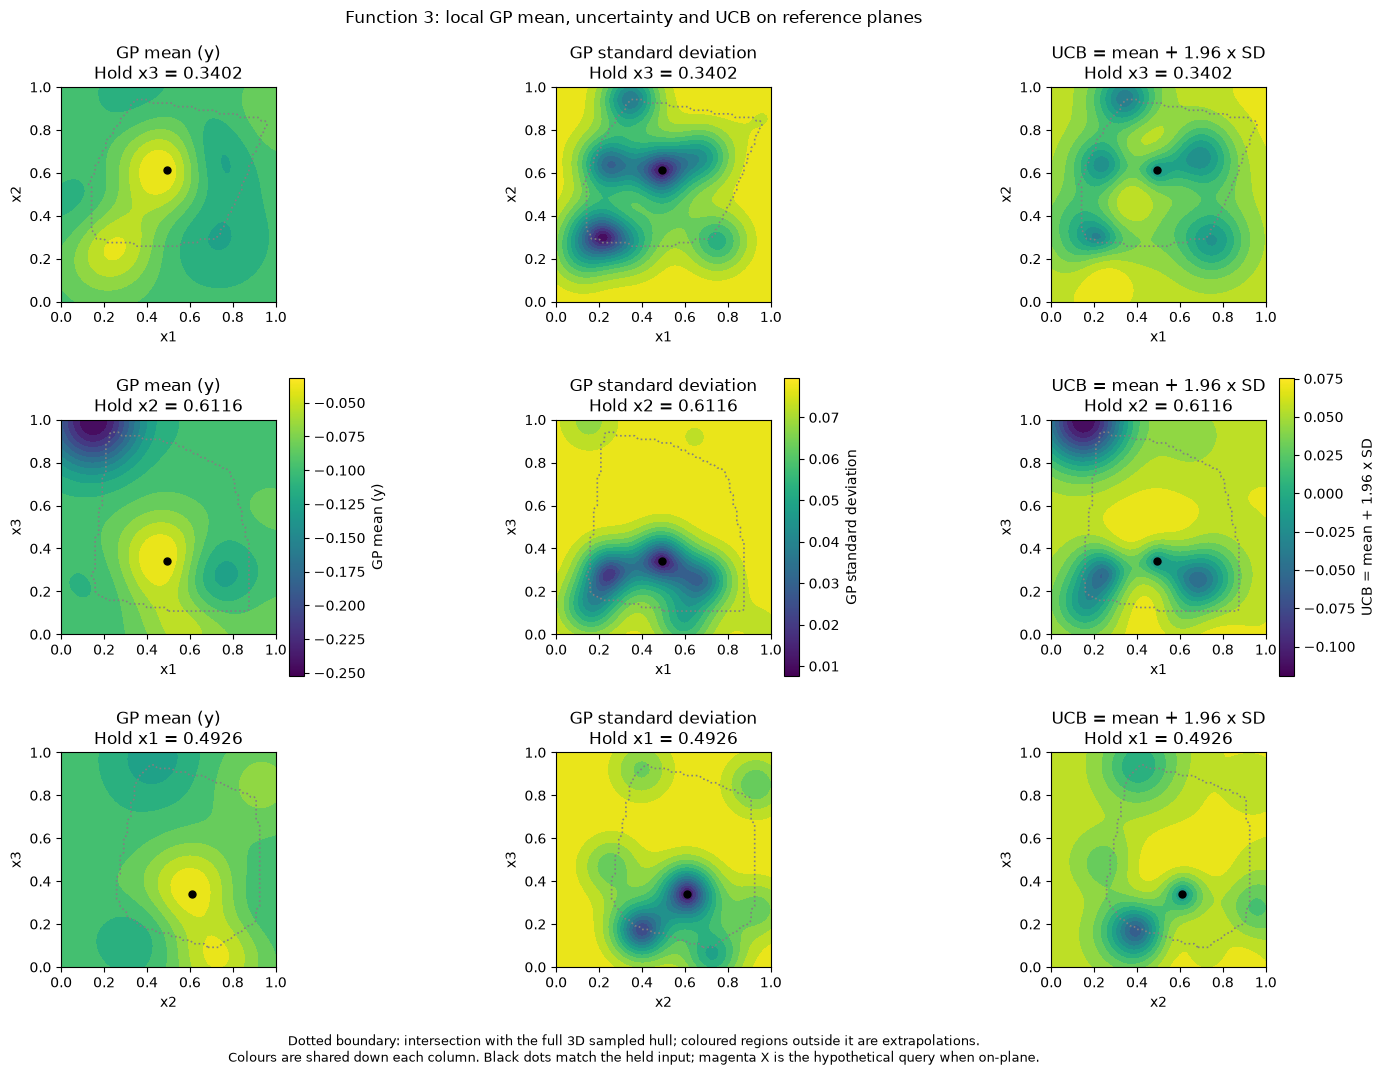

,x1,x2,x3,GP mean y,GP SD y,Illustrative UCB
2,0.903842,0.268903,0.8752,-0.100456,0.078499,0.053402


Actual coverage-led input remains: 0.903842-0.268903-0.875200


In [12]:
exploration_weight = 1.96
display(plot_gp_score_sections(anchor_gp_planes, inputs, weight=exploration_weight,
    title="Function 3: local GP mean, uncertainty and UCB on reference planes",
    save_to=figures / "gp-mean-uncertainty-ucb-slices.png"))
plan_mean, plan_std = local_gp.predict(planned_inputs, return_std=True)
plan_review = coverage_queries.copy()
plan_review["GP mean y"] = plan_mean
plan_review["GP SD y"] = plan_std
plan_review["Illustrative UCB"] = plan_mean + exploration_weight * plan_std
display(plan_review)
print("Actual coverage-led input remains:", actual_portal_input)


## 10. If we switched today: a hypothetical model-led next query

Choose the lower-LOO-MAE GP among the two fixed GP comparisons, then maximise `mean + 1.96 * SD`
over 4,096 seeded **three-dimensional** Sobol points plus the eight allowed extreme corners.
Round coordinates to six decimals before predicting, remove duplicates and already observed coordinates, then score those exact inputs.
The winner is the best of this finite pool, not a proven continuous optimum. Candidates outside the sampled hull are permitted and labelled.

A GP is used here because this rule needs both a mean and uncertainty; the lowest-error model overall may be a different regressor.
The chosen GP's MAE ratio is printed beside the suggestion. A ratio of 1 or more means it does not beat the mean baseline.
The weight sensitivity table reuses the same predictions, with no additional fits or course evaluations.
This hypothetical policy leaves the saved coverage decision unchanged.

The proposed mean is compared with the best measured output. UCB can select a point with a lower mean because its uncertainty may make it informative; a high score does not predict a new best result.


In [13]:
gp_names = [name for name in comparison.index if name.startswith("GP:")]
proposal_gp_name = comparison.loc[gp_names, "LOO MAE"].idxmin()
proposal_gp = fitted[proposal_gp_name]
proposal_relative_error = comparison.loc[proposal_gp_name, "MAE / baseline"]
query_candidates = make_query_candidates(inputs, power=12, seed=42)
scored_candidates = score_query_candidates(proposal_gp, query_candidates, weight=exploration_weight)
hypothetical_query = scored_candidates.iloc[0].copy()
hypothetical_inputs = hypothetical_query[input_columns].to_numpy(dtype=float)
hypothetical_portal_input = "-".join(f"{value:.6f}" for value in hypothetical_inputs)
hypothetical_inside_hull = bool(Delaunay(inputs).find_simplex(hypothetical_inputs) >= 0)
print("Hypothetical GP policy:", proposal_gp_name)
print(f"Chosen GP held-out MAE / mean baseline: {proposal_relative_error:.3f}")
if proposal_relative_error >= 1:
    print("Predictive check: this GP performs worse than the mean baseline; its suggested point is illustrative.")
print("Lowest-error model overall:", best_checked_model)
print(f"Candidate count after rounding and exclusions: {len(scored_candidates):,}")
print("Suggested model-led input (counterfactual):", hypothetical_portal_input)
print(f"Posterior mean: {hypothetical_query['posterior_mean']:.6f}; SD: {hypothetical_query['posterior_sd']:.6f}; UCB: {hypothetical_query['ucb']:.6f} (raw output units)")
print(f"Best observed output: {raw_y.max():.6f}; proposed mean minus best observed: {hypothetical_query['posterior_mean']-raw_y.max():.6f}")
print("Inside sampled hull:", hypothetical_inside_hull)
display(scored_candidates.head(5))
weight_sensitivity = []
for weight in [0.0, 1.0, 1.96, 3.0]:
    scores = scored_candidates["posterior_mean"] + weight * scored_candidates["posterior_sd"]
    alternative = scored_candidates.loc[scores.idxmax()]
    weight_sensitivity.append({"Weight": weight, **alternative[input_columns].to_dict(),
        "Mean": alternative["posterior_mean"], "SD": alternative["posterior_sd"],
        "Score": alternative["posterior_mean"] + weight * alternative["posterior_sd"]})
display(pd.DataFrame(weight_sensitivity))
print("Actual coverage-led input remains:", actual_portal_input)


Hypothetical GP policy: GP: local (l=0.15)
Chosen GP held-out MAE / mean baseline: 0.950
Lowest-error model overall: GP: local (l=0.15)
Candidate count after rounding and exclusions: 4,104
Suggested model-led input (counterfactual): 0.387386-0.545289-0.521335
Posterior mean: -0.067564; SD: 0.073114; UCB: 0.075739 (raw output units)
Best observed output: -0.034835; proposed mean minus best observed: -0.032728
Inside sampled hull: True


,x1,x2,x3,posterior_mean,posterior_sd,ucb
0,0.387386,0.545289,0.521335,-0.067564,0.073114,0.075739
1,0.709584,0.907420,0.029090,-0.066227,0.072351,0.075581
2,0.377400,0.561668,0.482325,-0.058984,0.068503,0.075282
3,0.417254,0.606300,0.533629,-0.067084,0.072526,0.075067
4,0.407130,0.486631,0.473870,-0.059225,0.068478,0.074991


,Weight,x1,x2,x3,Mean,SD,Score
0,0.00,0.443792,0.612630,0.343344,-0.032441,0.020809,-0.032441
1,1.00,0.392920,0.484250,0.394957,-0.049605,0.061098,0.011493
2,1.96,0.387386,0.545289,0.521335,-0.067564,0.073114,0.075739
3,3.00,0.405625,0.655286,0.560813,-0.075655,0.075894,0.152026


Actual coverage-led input remains: 0.903842-0.268903-0.875200


## 11. Locate the hypothetical point without flattening away an input

The cloud puts actual coverage and hypothetical GP-UCB inputs at their real three-dimensional coordinates.
Both are unevaluated: their fixed marker colours do not represent measured outputs.
Drag to inspect their relationship with the observations.

Then repeat the mean, SD and UCB panels on three planes **through the hypothetical point**.
Each panel holds the third coordinate at the proposal's value, so its magenta X really belongs to that section.
The actual coverage point is not projected onto these planes. Read the held values and hull intersections before interpreting a colourful peak.


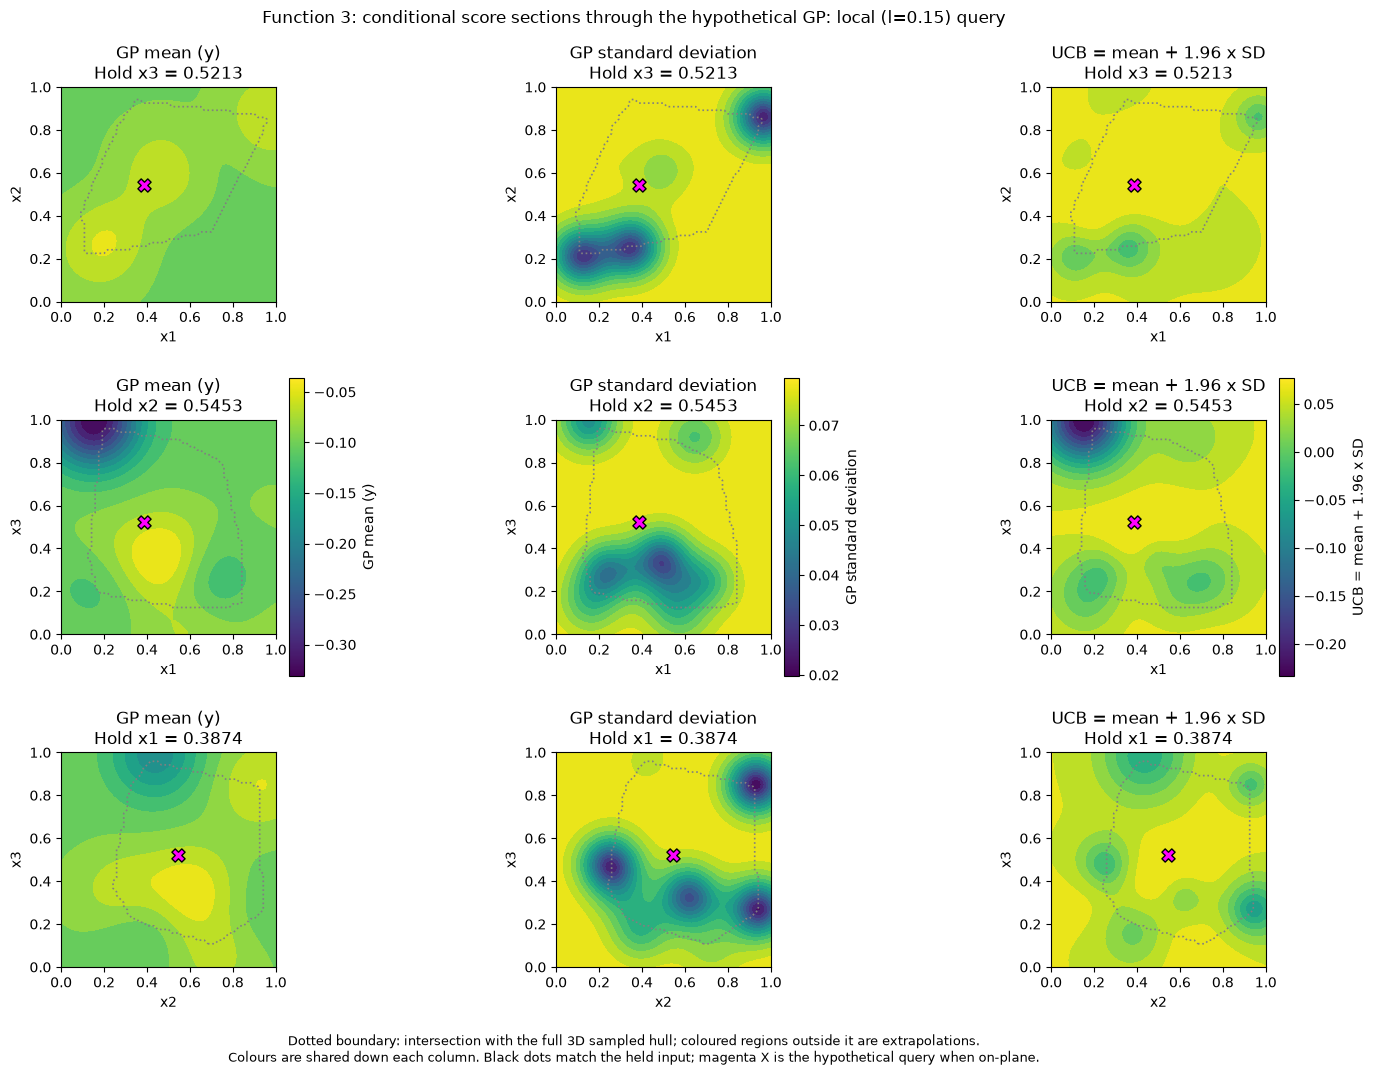

In [14]:
proposal_cloud = input_cloud(inputs, model_y,
    title="Function 3: actual coverage point and hypothetical model-led query",
    planned=planned_inputs[0], suggestion=hypothetical_inputs,
    save_to=figures / "model-query-proposal.html")
proposal_cloud.show(config=PLOT_CONFIG)
proposal_planes = [plane_grid(proposal_gp, inputs, (a,b), hypothetical_inputs[c], uncertainty=True)
                   for a,b,c in PLANE_AXES]
display(plot_gp_score_sections(proposal_planes, inputs, weight=exploration_weight,
    suggestion=hypothetical_inputs, title=f"Function 3: conditional score sections through the hypothetical {proposal_gp_name} query",
    save_to=figures / "model-query-proposal-slices.png"))


## Read the pictures in the same order each time

1. Identify which axes are inputs and which visual quantity represents output.
2. For a curve, name both held inputs; for a contour map, name the held third input.
3. Read the fitted mean, then its model band or SD, and compare held-out errors with the mean baseline.
4. Check whether the location is inside the full 3D sampled hull or is an extrapolation.
5. Separate measured results, a model's suggested query and the actual coverage policy.

The black box remains unknown. A narrow band, smooth contour or high UCB does not establish a real optimum.
The comparisons use 18 observations, including any model-selection choices made here.
For Week 4, the [exploration notebook's saved coverage sequence](exploration.ipynb) remains the actual query decision.
